In [30]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from torch.utils.data import random_split
import numpy as np

torch.manual_seed(0)
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Using device:", device)

Using device: mps


In [31]:
classes = ["cat", "dog", "house", "car", "tree", "apple", "fish", "bicycle", "star", "airplane"]
n_per_class = 30000

X_list, y_list = [], []
for label, cls in enumerate(classes):
    arr = np.load(f"data/{cls}.npy")[:n_per_class]
    X_list.append(arr)
    y_list.append(np.full(len(arr), label))

print(X_list[0].shape, y_list[0][:5])

(30000, 784) [0 0 0 0 0]


In [32]:
X = np.concatenate(X_list)
y = np.concatenate(y_list)

X = X.reshape(-1, 1, 28, 28).astype(np.float32)
X = X / 255.0
X = (X - 0.5) / 0.5

print(X.shape, y.shape, X.min(), X.max())

(300000, 1, 28, 28) (300000,) -1.0 1.0


In [33]:
X_tensor = torch.from_numpy(X)
y_tensor = torch.from_numpy(y).long()

dataset = TensorDataset(X_tensor, y_tensor)
img, label = dataset[0]
print(len(dataset), img.shape, label)

300000 torch.Size([1, 28, 28]) tensor(0)


In [34]:
generator = torch.Generator().manual_seed(42)
train_data, test_data = random_split(dataset, [0.8, 0.2], generator=generator)
train_set, val_set = random_split(train_data, [0.9, 0.1], generator=generator)

print(len(train_set), len(val_set), len(test_data))

216000 24000 60000


In [35]:
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape, labels.shape)
print(labels[0])

torch.Size([128, 1, 28, 28]) torch.Size([128])
tensor(2)


torch.Size([128, 1, 28, 28])
torch.Size([128])


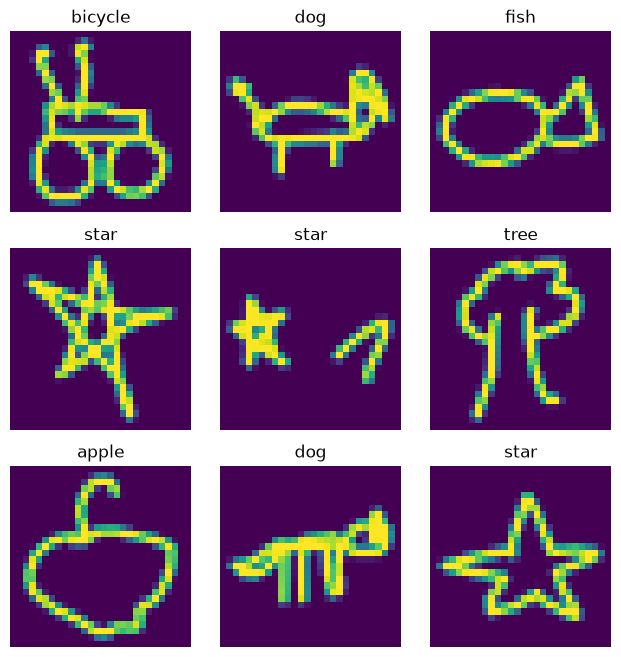

In [43]:
images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0) * 0.5 + 0.5)
    ax.set_title(classes[labels[i]], fontsize=12)
    ax.axis("off")

plt.subplots_adjust(wspace=0.05, hspace=0.2)
plt.savefig("images/samples.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),    # (32, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # (32, 14, 14)

            nn.Conv2d(32, 64, kernel_size=3, padding=1),   # (64, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # (64, 7, 7)

            nn.Conv2d(64, 128, kernel_size=3, padding=1),  # (128, 7, 7)
            nn.ReLU(),
            nn.MaxPool2d(2),                               # (128, 3, 3)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # 128 * 3 * 3 = 1152
            nn.Linear(1152, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [38]:
model = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)

In [39]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0,0,0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
            
    return total_loss / total, correct / total

In [41]:
epochs = 10
best_val_loss = float("inf")
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss, train_acc = evaluate(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pt")

    print(f"Epoch {epoch+1}: train loss {train_loss:.4f}, acc {train_acc:.4f} | val loss {val_loss:.4f}, acc {val_acc:.4f}")

Epoch 1: train loss 0.1396, acc 0.9527 | val loss 0.1752, acc 0.9435
Epoch 2: train loss 0.1275, acc 0.9568 | val loss 0.1674, acc 0.9466
Epoch 3: train loss 0.1245, acc 0.9575 | val loss 0.1710, acc 0.9440
Epoch 4: train loss 0.1111, acc 0.9613 | val loss 0.1671, acc 0.9470
Epoch 5: train loss 0.1043, acc 0.9643 | val loss 0.1641, acc 0.9465
Epoch 6: train loss 0.0974, acc 0.9661 | val loss 0.1658, acc 0.9474
Epoch 7: train loss 0.0910, acc 0.9681 | val loss 0.1678, acc 0.9470
Epoch 8: train loss 0.0856, acc 0.9703 | val loss 0.1685, acc 0.9479
Epoch 9: train loss 0.0804, acc 0.9722 | val loss 0.1726, acc 0.9476
Epoch 10: train loss 0.0766, acc 0.9739 | val loss 0.1726, acc 0.9478


In [42]:
model.load_state_dict(torch.load("best_model.pt"))
test_loss, test_acc = evaluate(model, test_loader)
print(test_loss, test_acc)

0.1737997850894928 0.9442666666666667


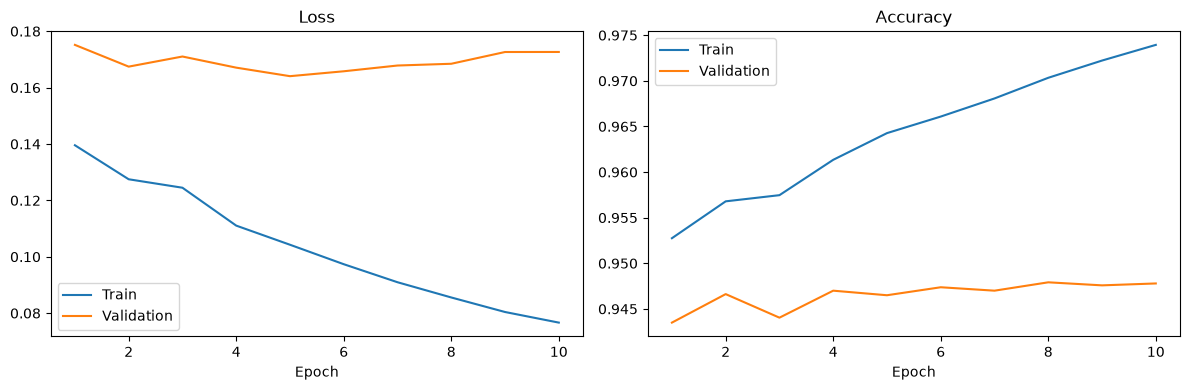

In [44]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["train_acc"], label="Train")
ax2.plot(epochs_range, history["val_acc"], label="Validation")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.savefig("images/model.png", dpi=150, bbox_inches="tight")
plt.show()